In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
import geopandas as gpd
from geopandas import GeoDataFrame
from shapely.geometry import Point


/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/cfgrib_.py:27: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [2]:

def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))
#restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
#restrepo_features_path = Path("/gxfs_work/cau/sunms498/work_old/Data/Features_PhrampusLee_noNaN_highres_rot/")
restrepo_features_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    #print(filenames)
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)


feature_selection = pd.read_csv(Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/selectedFeatureLists/selectedfeatures_v_men.txt")).values
#feature_selection = pd.read_csv(Path("restrepoHighResFeaturesRaw-50.txt")).values



In [3]:

selection_filter = np.zeros(len(restrepo_files), dtype=bool)
for idx, feature_name in enumerate(restrepo_files):
    if feature_name in feature_selection: # drop '.nc' from feature names #drop .grd
        selection_filter[idx] = True
feature_selection.shape
filenames
selected_files = []
for file in restrepo_files:
    if file in feature_selection:
        selected_files.append(file)
len(feature_selection)
restrepo_files = selected_files
restrepo_files
file_idx = -1
corrupted_files = 0


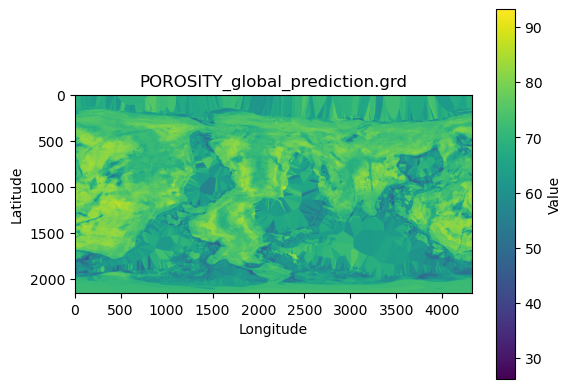

In [14]:
# plot the porosity file
for file in restrepo_files:
    if file == "POROSITY_global_prediction.grd":
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'GRIB2')
        data = rootgrp.variables['data'][:]
        lats = rootgrp.variables['lat'][:]
        lons = rootgrp.variables['lon'][:]
        plt.imshow(data, cmap='viridis')
        plt.colorbar(label='Value')
        plt.title(file)
        plt.xlabel('Longitude')
        plt.ylabel('Latitude') 
        plt.show()

<xarray.IndexVariable 'lat' (lat: 2160)>
array([-90.      , -89.916626, -89.83326 , ...,  89.83326 ,  89.916626,
        90.      ], dtype=float32)
<xarray.IndexVariable 'lon' (lon: 4320)>
array([ 180.     ,  179.91664,  179.8333 , ..., -179.8333 , -179.91664,
       -180.     ], dtype=float32)


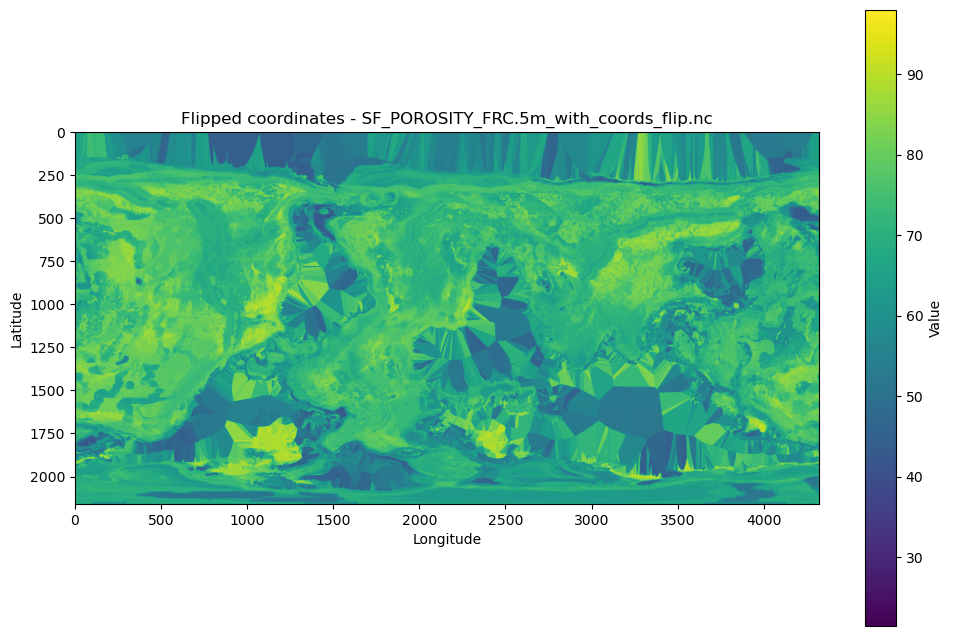

<xarray.IndexVariable 'lat' (lat: 2160)>
array([-90.      , -89.916626, -89.83326 , ...,  89.83326 ,  89.916626,
        90.      ], dtype=float32)
<xarray.IndexVariable 'lon' (lon: 4320)>
array([ 180.     ,  179.91664,  179.8333 , ..., -179.8333 , -179.91664,
       -180.     ], dtype=float32)


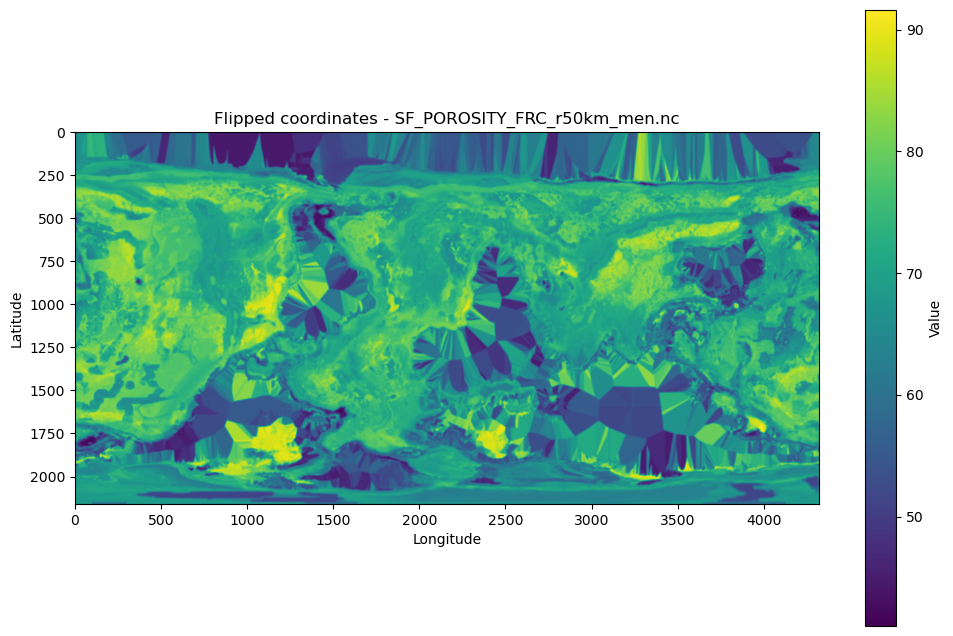

<xarray.IndexVariable 'lat' (lat: 2160)>
array([-90.      , -89.916626, -89.83326 , ...,  89.83326 ,  89.916626,
        90.      ], dtype=float32)
<xarray.IndexVariable 'lon' (lon: 4320)>
array([ 180.     ,  179.91664,  179.8333 , ..., -179.8333 , -179.91664,
       -180.     ], dtype=float32)


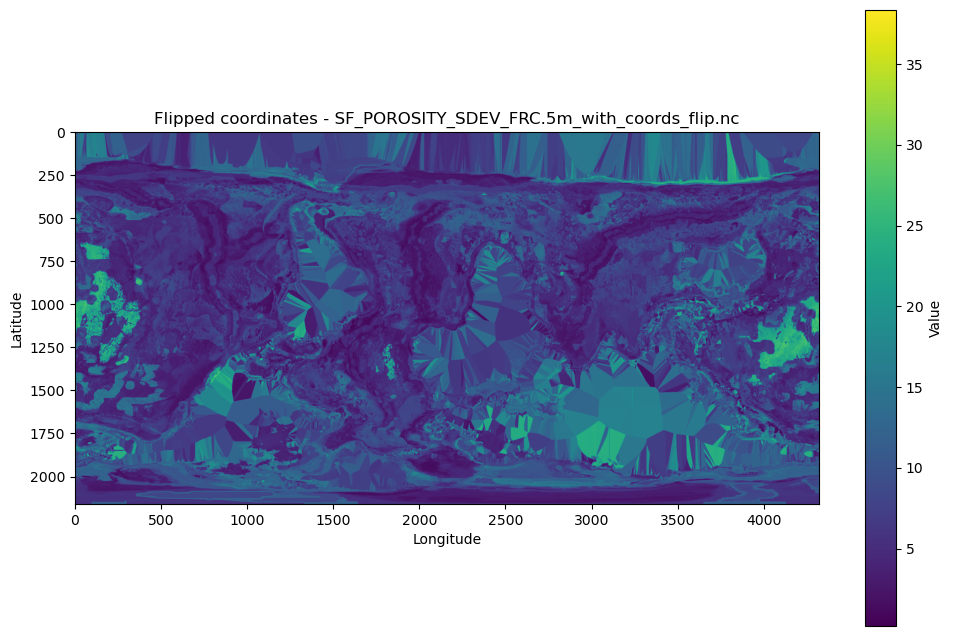

In [23]:
files_to_plot = [
    "SF_POROSITY_FRC.5m_with_coords_flip.nc",
    "SF_POROSITY_FRC_r50km_men.nc",
    "SF_POROSITY_SDEV_FRC.5m_with_coords_flip.nc"
]

file_idx = -1
corrupted_files = 0

for file in files_to_plot:
    file_idx += 1
    
    try:
        # Open original file
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        
        # Get original data and coordinates
        data = rootgrp.variables['data'][:]
        lats = rootgrp.variables['lat'][:]
        lons = rootgrp.variables['lon'][:]
        
        # Flip coordinates and data
        flipped_lats = lats[::-1]  # Reverse latitude order
        #flipped_lons = lons[::-1]  # Reverse longitude order
        flipped_data = data[:, :]  # Flip data in one dimensions
        print(flipped_lats)
        print(flipped_lons)
        #print(flipped_data)
        # Create new dataset with flipped coordinates and data
        new_ds = xr.Dataset(
            data_vars={
                'data': (['lat', 'lon'], flipped_data)
            },
            coords={
                'lat': flipped_lats,
                'lon': flipped_lons
            }
        )
        
        # Save flipped file
        new_filename = 'flipped_' + file
        new_ds.to_netcdf(Path(restrepo_features_path / new_filename))
        
        # Plot to verify
        plt.figure(figsize=(12,8))
        plt.imshow(flipped_data, cmap='viridis')
        plt.colorbar(label='Value')
        plt.title(f'Flipped coordinates - {file}')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        plt.show()

    except Exception as e:
        print(f"Error processing {file}: {str(e)}")
        corrupted_files += 1
        continue